# Digital Detective: Feature Extraction Challenge
This interactive notebook allows you to run computer vision algorithms (ORB) to extract and match visual features between images, simulating a digital detective searching for clues.

In [7]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Helper function to display images properly in Jupyter/Colab
def show_img(title, img):
    plt.figure(figsize=(12, 8))
    # Convert BGR (OpenCV default) to RGB (Matplotlib default)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

## Step 1: Load and Prepare Images
Make sure you have uploaded `Cup.jpeg` and `Table.jpeg` to your Colab environment or local directory before running this cell.

Images successfully loaded and converted to grayscale.


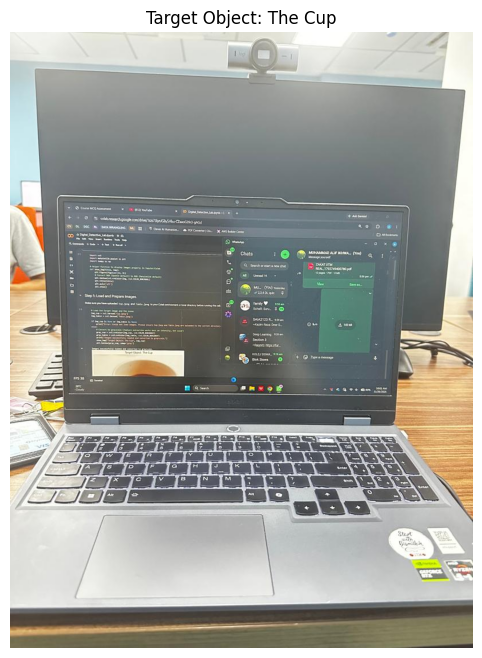

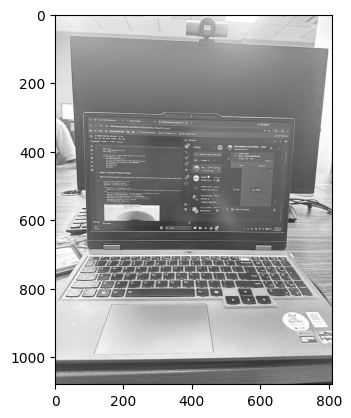

In [8]:
# Load the target image and the scene
img_cup = cv2.imread('laptop.jpeg')
img_table = cv2.imread('laptop2.jpeg')

if img_cup is None or img_table is None:
    print("Error: Could not load images. Please ensure Cup.jpeg and Table.jpeg are uploaded to the current directory.")
else:
    # Convert to grayscale (feature extraction works best on intensity, not color)
    gray_cup = cv2.cvtColor(img_cup, cv2.COLOR_BGR2GRAY)
    gray_table = cv2.cvtColor(img_table, cv2.COLOR_BGR2GRAY)
    print("Images successfully loaded and converted to grayscale.")
    show_img("Target Object: The Cup", img_cup)
    plt.imshow(gray_cup, cmap='gray')

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Step 2: Extract Features using ORB
Here, the computer acts as the detective, identifying keypoints (distinctive corners and edges) and calculating their mathematical descriptors.

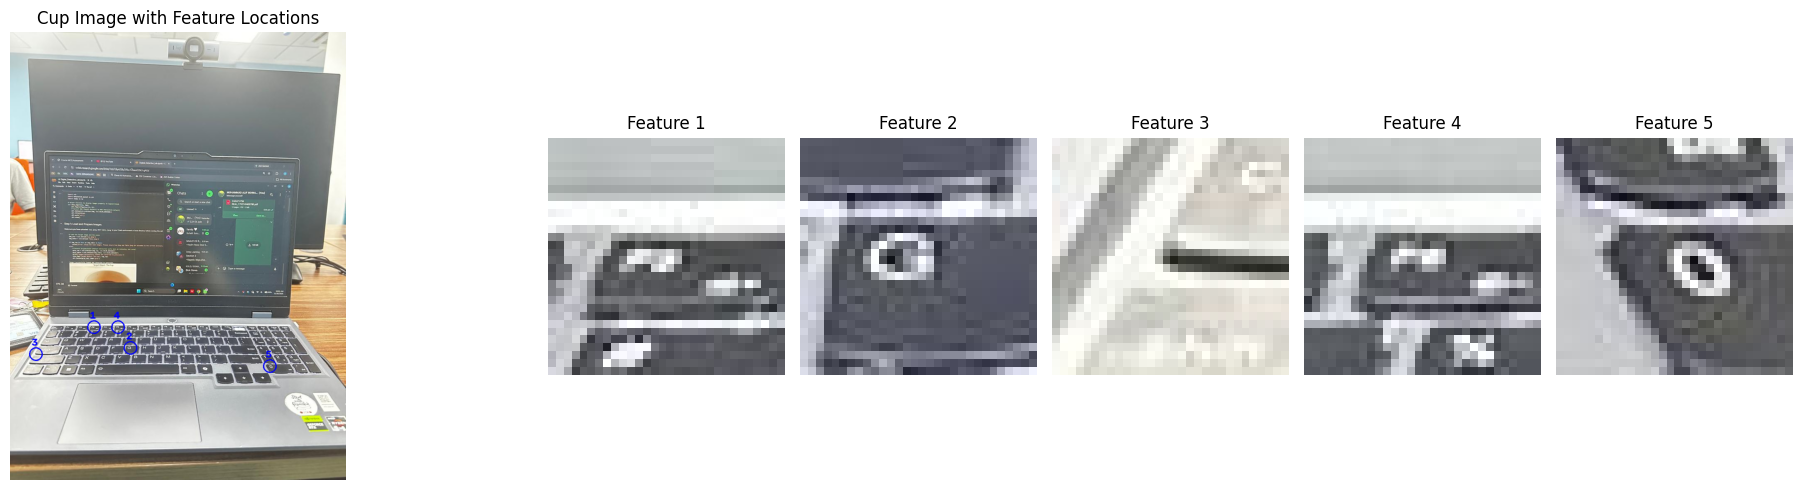

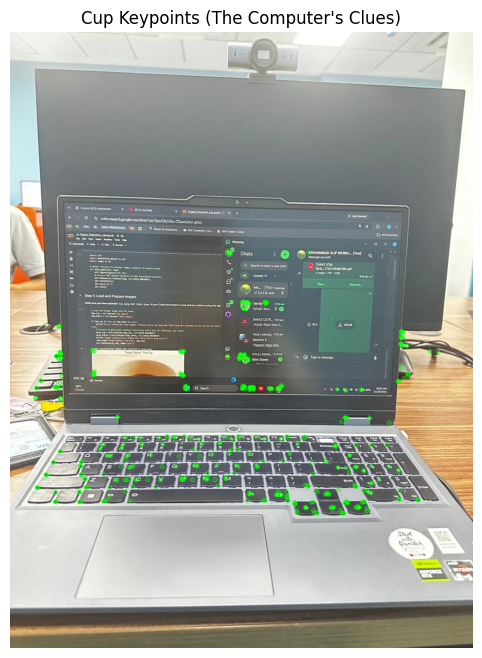

In [10]:
# Initialize the ORB detector (finding up to 500 features)
orb = cv2.ORB_create(nfeatures=500)

# Detect keypoints and compute descriptors
kp_cup, des_cup = orb.detectAndCompute(gray_cup, None)
kp_table, des_table = orb.detectAndCompute(gray_table, None)


# 1. Setup a figure with 6 subplots (1 large for the main image, 5 small for the patches)
fig, axes = plt.subplots(1, 6, figsize=(20, 5), gridspec_kw={'width_ratios': [3, 1, 1, 1, 1, 1]})

# 2. Create a copy of the original cup image to draw annotations on
img_cup_annotated = img_cup.copy()
offset = 15 # 15 pixels in every direction creates a 30x30 patch

# 3. Loop through the first 5 detected keypoints
for i in range(5):
    kp = kp_cup[i]
    x, y = int(kp.pt[0]), int(kp.pt[1])

    # Draw a numbered blue circle on the main image at the keypoint's exact location
    cv2.circle(img_cup_annotated, (x, y), offset, (255, 0, 0), 2)
    cv2.putText(img_cup_annotated, str(i+1), (x - 10, y - 20),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)

    # Crop the pixel patch, using min/max to prevent errors if a point is near the image edge
    patch = img_cup[max(0, y - offset) : min(img_cup.shape[0], y + offset),
                    max(0, x - offset) : min(img_cup.shape[1], x + offset)]

    # Display the cropped patch in its respective subplot
    axes[i+1].imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
    axes[i+1].set_title(f"Feature {i+1}")
    axes[i+1].axis('off')

# 4. Display the annotated main image in the first subplot
axes[0].imshow(cv2.cvtColor(img_cup_annotated, cv2.COLOR_BGR2RGB))
axes[0].set_title("Cup Image with Feature Locations")
axes[0].axis('off')

plt.tight_layout()
plt.show()


# Visualize the keypoints found on the cup
img_cup_kp = cv2.drawKeypoints(img_cup, kp_cup, None, color=(0, 255, 0), flags=0)
show_img("Cup Keypoints (The Computer's Clues)", img_cup_kp)

## Step 3 & 4: Match Features and Analyze the Results
The computer now compares the descriptors from the cup against the descriptors found in the cluttered scene to find matches.

Total features matched: 152


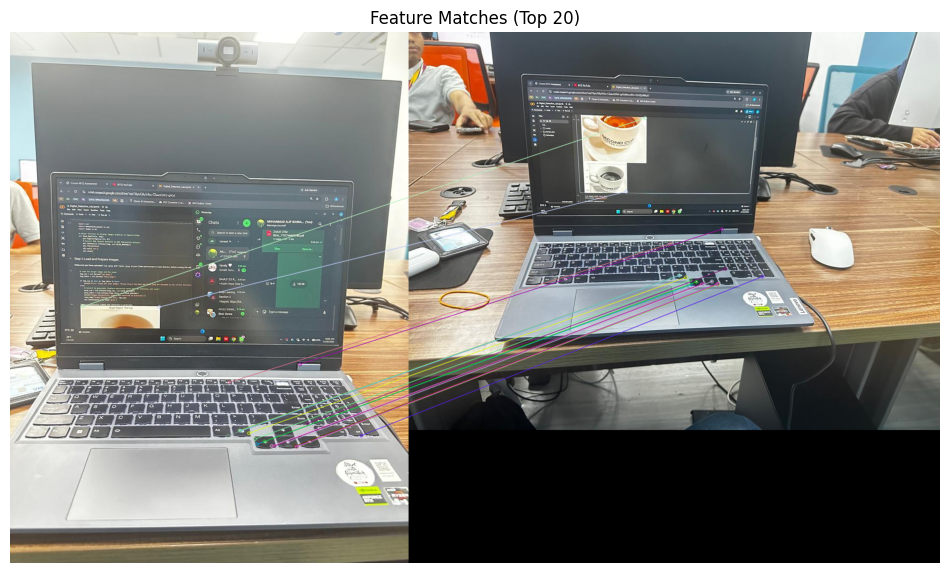

In [11]:
# Create a Brute-Force Matcher to compare descriptor distances (Hamming distance for ORB)
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

# Match descriptors between the cup and the table
matches = bf.match(des_cup, des_table)

# Sort the matches based on how similar they are (lower distance = better match)
matches = sorted(matches, key=lambda x: x.distance)

print(f"Total features matched: {len(matches)}")

# Draw the top 20 best matches to avoid visual clutter
img_matches = cv2.drawMatches(
    img_cup, kp_cup,
    img_table, kp_table,
    matches[:20], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

show_img("Feature Matches (Top 20)", img_matches)